In [387]:
## This is the import cell it should be run everytime you reopen the code.
import math as math
import pandas as pd
import numpy as np
import dcor
import hyppo
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
from scipy import stats
from scipy.stats import boxcox
import os
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [388]:
#This cell is where  commonly used items are defined in case they need to be changed
#This way if a change is needed one change is only needed rather than 20
#This cell will not produce an error if run before the data cells because it creates the lists
#This cell does not reflect the order of the procedure it exits purely for convience

data_location = "F:/NonParametric Methods/Final Project/Merged Datasets"
test_location = "F:/NonParametric Methods/Final Project/Statical Tests"
histogram_location = "F:/NonParametric Methods/Final Project/Data Plots/Histograms"
boxplot_location = "F:/NonParametric Methods/Final Project/Data Plots/Boxplots"
boxplot_location2 = "F:/NonParametric Methods/Final Project/Data Plots/Boxplots (without outliers)"
regression_location = "F:/NonParametric Methods/Final Project/Linear Regression Outputs"

# Removed for hig vif
"Net official development assistance received (Millions US$)"
"Grants, excluding technical cooperation (BoP, Millions US$)"

response_variable = "Treasury Bill Rate (%)"

time_independent_variables = [
    "Access to electricity (% of population)",
    "Broad money (% of GDP)",
    "Broad money to total reserves ratio",
    "Claims on central government (annual growth as % of broad money)",
    "Claims on central government, etc. (% GDP)",
    "Combustible renewables and waste (% of total energy)",
    "Electricity production from natural gas sources (% of total)",
    "Electricity production from oil sources (% of total)",
    "Energy imports, net (% of energy use)",
    "Natural gas rents (% of GDP)",
    "Oil rents (% of GDP)",
    "PPG, official creditors (NFL, Millions US$)",
    "Short-term debt (% of total reserves)",
    "Use of IMF credit (DOD, Millions US$)"]

In [389]:
#Creating and Defining Functions

def export_to_excel(folder_location:str, file_name:str, data_frame):
    """This function stores as dataframe as an excell spreadsheet
    in the specified folder with the specified file name"""

    path = os.path.join(folder_location,file_name + ".xlsx")
    data_frame.to_excel(path)
    print("Your data has been exported to", path)



def my_histogram(folder_location:str, indicator:str, data_frame: pd.DataFrame):
    """This function produces a histogram and stores the histogram
    in the specified folder with the specified file name"""
    name = 'Histogram of ' + indicator

    #Creating the path to store the output
    path = os.path.join(folder_location, name + ".png")

    # Non-missing observations for the plots and statistics
    all_data = data_frame[indicator]
    data = all_data.dropna()

    #Creating the five number summary
    N = data.count()
    minimum = data.min()
    q1 = data.quantile(0.25)
    median = data.median()
    q3 = data.quantile(0.75)
    maximum = data.max()
    mean = data.mean()
    sd = data.std()
    missing = data.isna().sum()
    # Create summary text in the requested order
    summary_text = (
        f"N: {N}   Min: {minimum:.2f}   Q1: {q1:.2f}   "
        f"Median: {median:.2f}   Q3: {q3:.2f}\n"
        f"Max: {maximum:.2f}   Mean: {mean:.2f}   "
        f"SD: {sd:.2f}   Missing: {missing}"
        )

    # Create figure
    fig, (ax_hist, ax_box) = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    gridspec_kw={
        "height_ratios": [4, 1],
        "hspace": 0.05}
        )

    # Histogram
    sns.histplot(
        data,
        bins=20,
        kde=True,
        ax=ax_hist
        )
    
    # Mean line
    ax_hist.axvline(
        mean,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean:.2f}"
        )
    ax_hist.set_ylabel("Frequency")
    ax_hist.set_title(f"Distribution of {indicator}")
    ax_hist.legend()

    # Summary statistics above the histogram
    ax_hist.text(
        0.5, 1.12,
        summary_text,
        transform=ax_hist.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
            )
            )

    # Horizontal box plot
    sns.boxplot(
        x=data,
        ax=ax_box,
        orient="h"
        )
    ax_box.set_xlabel(indicator)
    ax_box.set_ylabel("")
    ax_box.grid(axis="x", alpha=0.3)

    # Hide histogram x-axis labels
    ax_hist.tick_params(axis="x", labelbottom=False)

    # Make room for summary statistics
    plt.subplots_adjust(top=0.80)
    plt.savefig(path)
    plt.show()
    print("Your Histogram has been saved to ", path)

def stratfiedboxplots(folder_location:str, indicator: str, category: str, dataframe: pd.DataFrame):
    """Produces Side by Side Boxplots of indicator stratified by the variable category"""
    name = "Stratified Box Plots of " + indicator + " by" + category + ".png"
    path = os.path.join(folder_location, name)
    
    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=dataframe,
        x=category,
        y=indicator
    )
    plt.title(indicator + " by Year")
    plt.xlabel(category)
    plt.ylabel(indicator)
    plt.savefig(path)
    plt.show()
    print("Your Boxplot have been saved to ", path)



def stratfiedboxplots2(folder_location:str, indicator: str, category: str, dataframe: pd.DataFrame):

    name = "Stratified Box Plots of " + indicator + " by" + category + "excluding outliers.png"
    path = os.path.join(folder_location, name)
    
    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=dataframe,
        x=category,
        y=indicator,
        whis = 1.5,
        showfliers=False
    )
    plt.title(indicator + " by Year ")
    plt.xlabel(category)
    plt.ylabel(indicator)
    plt.savefig(path)
    plt.show()
    print("Your Boxplot have been saved to ", path)


def regression_cycle(folder_location: str,
                     response_variable: str,
                     explanitory_variables: list,
                     year: str,
                     dataframe: pd.DataFrame):

    # --------------------------------------------------
    # 1. Create output directories and file paths
    # --------------------------------------------------

    os.makedirs(folder_location, exist_ok=True)

    # Remove characters invalid in Windows filenames
    safe_response = "".join(
        "_" if char in '<>:"/\\|?*' else char
        for char in response_variable
    )

    name = f"MLR of {safe_response} for the year {year}"
    path = os.path.join(folder_location, name + ".xlsx")

    # --------------------------------------------------
    # 2. Prepare regression data
    # --------------------------------------------------

    regression_vars = [response_variable] + explanitory_variables

    subset = (
        dataframe.loc[
            dataframe["Year"] == year,
            regression_vars
        ]
        .dropna()
    )

    if subset.empty:
        print(f"Skipping {year}: no complete observations.")
        return

    if not explanitory_variables:
        print(f"Skipping {year}: no explanatory variables supplied.")
        return

    y = subset[response_variable]
    remaining_vars = list(explanitory_variables)

    # --------------------------------------------------
    # 3. Variable selection using VIF
    # --------------------------------------------------

    while True:

        # Fit model using current explanatory variables
        X = sm.add_constant(
            subset[remaining_vars],
            has_constant="add"
        )

        current_model = sm.OLS(y, X).fit()

        # Calculate VIF for current explanatory variables
        X_vif = subset[remaining_vars]

        vif_values = [
            variance_inflation_factor(X_vif.values, j)
            for j in range(X_vif.shape[1])
        ]

        vif_table = pd.DataFrame({
            "Variable": remaining_vars,
            "VIF": vif_values
        })

        max_vif = vif_table["VIF"].max()

        # Stop when all VIF values are below 2.5
        if max_vif < 2.5:
            print(
                f"Year {year}: VIF criterion satisfied. "
                f"Maximum VIF = {max_vif:.4f}"
            )
            break

        # Avoid removing the final explanatory variable
        if len(remaining_vars) == 1:
            print(
                f"Year {year}: Only one explanatory variable "
                f"remains, but its VIF is {max_vif:.4f}. "
                "Retaining the variable."
            )
            break

        print(
            f"Year {year}: Maximum VIF = {max_vif:.4f}. "
            "Evaluating variable removal."
        )

        # Adjusted R-squared of the current model
        current_adjusted_r2 = current_model.rsquared_adj

        differences = []

        # Evaluate removing each explanatory variable
        for variable in remaining_vars:

            reduced_vars = [
                var for var in remaining_vars
                if var != variable
            ]

            reduced_X = sm.add_constant(
                subset[reduced_vars],
                has_constant="add"
            )

            reduced_model = sm.OLS(y, reduced_X).fit()

            difference = (
                reduced_model.rsquared_adj
                - current_adjusted_r2
            )

            differences.append({
                "Indicator": variable,
                "Difference": difference
            })

        R_Square_Frame = pd.DataFrame(differences)

        # Identify removal producing the greatest
        # adjusted R-squared improvement (or smallest decline)
        worst_var = R_Square_Frame.loc[
            R_Square_Frame["Difference"].idxmax(),
            "Indicator"
        ]

        print(
            f"Year {year}: Removing {worst_var} "
            f"(Maximum VIF = {max_vif:.4f})"
        )

        remaining_vars.remove(worst_var)

    # --------------------------------------------------
    # 4. Fit the FINAL regression model
    # --------------------------------------------------

    X_final = sm.add_constant(
        subset[remaining_vars],
        has_constant="add"
    )

    final_model = sm.OLS(y, X_final).fit()

    # Recalculate VIF using the final explanatory variables
    final_vif_values = [
        variance_inflation_factor(
            subset[remaining_vars].values, j
        )
        for j in range(len(remaining_vars))
    ]

    vif_table = pd.DataFrame({
        "Variable": remaining_vars,
        "VIF": final_vif_values
    })

    print(
        f"Year {year}: Final model contains "
        f"{len(remaining_vars)} explanatory variables."
    )

    # --------------------------------------------------
    # 5. Prepare final regression results
    # --------------------------------------------------

    confidence_intervals = final_model.conf_int()

    regression_table = pd.DataFrame({
        "Variable": final_model.params.index,
        "Coefficient": final_model.params.values,
        "Std. Error": final_model.bse.values,
        "t-Statistic": final_model.tvalues.values,
        "p-Value": final_model.pvalues.values,
        "CI Lower": confidence_intervals[0].values,
        "CI Upper": confidence_intervals[1].values
    })

    primary_model_statistics = pd.DataFrame({
        "Statistic": [
            "Observations",
            "R-squared",
            "Adjusted R-squared",
            "F-statistic",
            "Prob (F-statistic)",
            "AIC",
            "BIC"
        ],
        "Value": [
            int(final_model.nobs),
            final_model.rsquared,
            final_model.rsquared_adj,
            final_model.fvalue,
            final_model.f_pvalue,
            final_model.aic,
            final_model.bic
        ]
    })

    # --------------------------------------------------
    # 6. Export final regression results to Excel
    # --------------------------------------------------

    with pd.ExcelWriter(path, engine="openpyxl") as writer:

        regression_table.to_excel(
            writer,
            sheet_name="Regression Results",
            index=False
        )

        primary_model_statistics.to_excel(
            writer,
            sheet_name="Model Statistics",
            index=False
        )

        vif_table.to_excel(
            writer,
            sheet_name="VIF",
            index=False
        )

    print(
        "Regression results exported to:",
        os.path.abspath(path)
    )

    # --------------------------------------------------
    # 7. Extract residuals from the FINAL model
    # --------------------------------------------------

    residuals = final_model.resid
    fitted_values = final_model.fittedvalues

    # --------------------------------------------------
    # 8. Create PowerPoint-matched diagnostic plots
    # --------------------------------------------------

    from scipy import stats

    # Colours sampled/approximated from the poster's palette
    GOLD = "#B5A052"
    CHARCOAL = "#2F3833"
    CREAM = "#F1ECD9"
    BURNT_ORANGE = "#B65E36"
    MUTED_BLUE = "#547D91"
    GRID = "#D9D2BE"
    WHITE = "#FFFFFF"

    plot_folder = os.path.join(
        folder_location,
        "Residual Analysis"
    )
    os.makedirs(plot_folder, exist_ok=True)

    # Consistent figure and axes styling
    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 10),
        facecolor=WHITE
    )

    fig.suptitle(
        f"Regression Diagnostic Plots | {response_variable} | {year}",
        fontsize=17,
        fontweight="bold",
        color=CHARCOAL,
        y=0.98
    )

    def style_axis(ax, title, xlabel, ylabel):

        ax.set_facecolor(CREAM)

        ax.set_title(
            title,
            fontsize=12,
            fontweight="bold",
            color=CHARCOAL,
            pad=12
        )

        ax.set_xlabel(
            xlabel,
            fontsize=10,
            color=CHARCOAL
        )

        ax.set_ylabel(
            ylabel,
            fontsize=10,
            color=CHARCOAL
        )

        ax.tick_params(
            axis="both",
            labelsize=9,
            colors=CHARCOAL
        )

        ax.grid(
            True,
            color=GRID,
            linestyle="-",
            linewidth=0.7,
            alpha=0.8
        )

        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color(CHARCOAL)
            spine.set_linewidth(0.8)


    # --------------------------------------------------
    # 1. Residuals vs Fitted Values
    # --------------------------------------------------

    ax = axes[0, 0]

    ax.scatter(
        fitted_values,
        residuals,
        color=MUTED_BLUE,
        edgecolor=CHARCOAL,
        linewidth=0.5,
        alpha=0.85,
        s=45
    )

    ax.axhline(
        0,
        color=BURNT_ORANGE,
        linestyle="--",
        linewidth=1.8
    )

    style_axis(
        ax,
        "Residuals vs Fitted Values",
        "Fitted Values",
        "Residuals"
    )


    # --------------------------------------------------
    # 2. Histogram of Residuals
    # --------------------------------------------------

    ax = axes[0, 1]

    ax.hist(
        residuals,
        bins="auto",
        density=True,
        color=GOLD,
        edgecolor=CHARCOAL,
        linewidth=0.8,
        alpha=0.85
    )

    residual_mean = residuals.mean()
    residual_std = residuals.std(ddof=1)

    if residual_std > 0:

        x_range = np.linspace(
            residuals.min(),
            residuals.max(),
            200
        )

        normal_curve = stats.norm.pdf(
            x_range,
            loc=residual_mean,
            scale=residual_std
        )

        ax.plot(
            x_range,
            normal_curve,
            color=BURNT_ORANGE,
            linewidth=2,
            linestyle="--",
            label="Normal Distribution"
        )

        ax.legend(
            frameon=False,
            fontsize=9,
            labelcolor=CHARCOAL
        )

    style_axis(
        ax,
        "Distribution of Residuals",
        "Residuals",
        "Density"
    )


    # --------------------------------------------------
    # 3. Normal Q-Q Plot
    # --------------------------------------------------

    ax = axes[1, 0]

    qq_data = stats.probplot(
        residuals,
        dist="norm"
    )

    theoretical_quantiles = qq_data[0][0]
    ordered_residuals = qq_data[0][1]
    slope, intercept, correlation = qq_data[1]

    ax.scatter(
        theoretical_quantiles,
        ordered_residuals,
        color=GOLD,
        edgecolor=CHARCOAL,
        linewidth=0.5,
        alpha=0.9,
        s=45
    )

    ax.plot(
        theoretical_quantiles,
        slope * theoretical_quantiles + intercept,
        color=BURNT_ORANGE,
        linewidth=2
    )

    style_axis(
        ax,
        "Normal Q-Q Plot",
        "Theoretical Quantiles",
        "Sample Quantiles"
    )


    # --------------------------------------------------
    # 4. Cook's Distance
    # --------------------------------------------------

    ax = axes[1, 1]

    influence = final_model.get_influence()
    cooks_d = influence.cooks_distance[0]

    threshold = 4 / final_model.nobs

    markerline, stemlines, baseline = ax.stem(
        np.arange(len(cooks_d)),
        cooks_d,
        basefmt=" "
    )

    plt.setp(
        markerline,
        marker="o",
        markersize=5,
        markerfacecolor=GOLD,
        markeredgecolor=CHARCOAL
    )

    plt.setp(
        stemlines,
        color=GOLD,
        linewidth=1.5
    )

    ax.axhline(
        threshold,
        color=BURNT_ORANGE,
        linestyle="--",
        linewidth=1.8,
        label=f"4/n threshold ({threshold:.3f})"
    )

    ax.legend(
        frameon=False,
        fontsize=9,
        labelcolor=CHARCOAL
    )

    style_axis(
        ax,
        "Cook's Distance",
        "Observation Index",
        "Cook's Distance"
    )


    # --------------------------------------------------
    # 9. Save the diagnostic figure
    # --------------------------------------------------
    from matplotlib.patches import Rectangle
    fig.add_artist(
        Rectangle(
        (0, 0),       # Bottom-left position
        1,                 # Width
        1,                 # Height
        transform=fig.transFigure,
        fill=False,
        edgecolor=CHARCOAL,
        linewidth=2,
        zorder=10
    ))

    fig.tight_layout(rect=[0, 0, 1, 0.95])

    plot_name = (
        f"Diagnostic_Plots_{safe_response}_{year}.png"
    )

    plot_path = os.path.join(
        plot_folder,
        plot_name
    )

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.close(fig)

    print(
        "Diagnostic plots exported to:",
        os.path.abspath(plot_path)
    )

In [390]:
# Importing the subsets of the WDI Dataset based on how they are stored in my computer
#Defining the name of the file and setting up the export location
name = "Project Merged Data"

EnergyAndMining_df = pd.read_csv("F:/NonParametric Methods/Final Project/Original Datasets/EnergyAndMining.csv")
Debt_df = pd.read_csv("F:/NonParametric Methods/Final Project/Original Datasets/ExternalDebt.csv")
Finance_df = pd.read_csv("F:/NonParametric Methods/Final Project/Original Datasets/FinancialSector.csv")

#This code deletes the years from 1960 to 2016 from the data set leaving the years 2017 to 2025.
#Observe that Finacnce_df1 is not the same as finance_df and we must use the new data going forward.
Debt_df1 = Debt_df.copy()
for i in range(4,61,1):
    Debt_df1 = Debt_df1.drop(Debt_df1.columns[4], axis =1)
Finance_df1 = Finance_df.copy()
for i in range(4,61,1):
    Finance_df1 = Finance_df1.drop(Finance_df1.columns[4], axis=1)
EnergyAndMining_df1 = EnergyAndMining_df.copy()
for i in range(4,61,1):
    EnergyAndMining_df1 = EnergyAndMining_df1.drop(EnergyAndMining_df1.columns[4], axis=1)

#This code merges the datasets but some data points are counted in multiple datasets and need to be removed.
Project_df = pd.concat([Debt_df1,Finance_df1,EnergyAndMining_df1], ignore_index=True)
#Removing Duplicate rows from the merged data set to avoid double counting at the country level.
Project_df = Project_df.drop_duplicates()

export_to_excel(folder_location = data_location, file_name = name, data_frame= Project_df)

Your data has been exported to F:/NonParametric Methods/Final Project/Merged Datasets\Project Merged Data.xlsx


In [391]:
#Getting rid of unwanted indicators
# Most of the code is a large list, the rest is a simple drop command
Keep_list = ["Access to electricity (% of population)",
"Adjusted savings: energy depletion (current US$)",
"Alternative and nuclear energy (% of total energy use)",
"Broad money (% of GDP)",
"Broad money to total reserves ratio",
"Claims on central government (annual growth as % of broad money)",
"Claims on central government, etc. (% GDP)",
"Combustible renewables and waste (% of total energy)",
"Consumer price index (2010 = 100)",
"Current account balance (BoP, current US$)",
"Debt service on external debt, public and publicly guaranteed (PPG) (TDS, current US$)",
"Debt service on external debt, total (TDS, current US$)",
"Electric power consumption (kWh per capita)",
"Electric power transmission and distribution losses (% of output)",
"Electricity production from coal sources (% of total)",
"Electricity production from hydroelectric sources (% of total)",
"Electricity production from natural gas sources (% of total)",
"Electricity production from nuclear sources (% of total)",
"Electricity production from oil sources (% of total)",
"Electricity production from oil, gas and coal sources (% of total)",
"Energy imports, net (% of energy use)",
"Energy use (kg of oil equivalent per capita)",
"External debt stocks, long-term (DOD, current US$)",
"External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)",
"External debt stocks, short-term (DOD, current US$)",
"External debt stocks, total (DOD, current US$)",
"Fossil fuel energy consumption (% of total)",
"GDP per unit of energy use (PPP $ per kg of oil equivalent)",
"Grants, excluding technical cooperation (BoP, current US$)",
"IBRD loans and IDA credits (DOD, current US$)",
"IMF repurchases and charges (TDS, current US$)",
"Investment in energy with private participation (current US$)",
"Lending interest rate (%)",
"Multilateral debt service (% of public and publicly guaranteed debt service)",
"Multilateral debt service (TDS, current US$)",
"Natural gas rents (% of GDP)",
"Net ODA received per capita (current US$)",
"Net official development assistance received (current US$)",
"Official exchange rate (LCU per US$, period average)",
"Oil rents (% of GDP)",
"PPG, bonds (NFL, current US$)",
"PPG, commercial banks (NFL, current US$)",
"PPG, IBRD (DOD, current US$)",
"PPG, IDA (DOD, current US$)",
"PPG, official creditors (NFL, US$)",
"PPG, other private creditors (NFL, current US$)",
"PPG, private creditors (NFL, US$)",
"Present value of external debt (current US$)",
"Public and publicly guaranteed debt service (% of exports of goods, services and primary income)",
"Renewable electricity output (% of total electricity output)",
"Renewable energy consumption (% of total final energy consumption)",
"Risk premium on lending (lending rate minus treasury bill rate, %)",
"Short-term debt (% of total reserves)",
"Total natural resources rents (% of GDP)",
"Total reserves (% of total external debt)",
"Use of IMF credit (DOD, current US$)"
]

Project_df = Project_df[Project_df["Indicator Name"].isin(Keep_list)]

In [392]:
#Transposing the data and storing the Transposed Data as well as removing certain missing values
#Converts the Years Columns into a single column
#Defining name for the export Function
name = "Project Transposed Data"

df_long = Project_df.melt(
    id_vars=[
        "Country Name",
        "Country Code",
        "Indicator Name",
        "Indicator Code"
    ],
    var_name="Year",
    value_name="Value"
)

#Makes each series its own coulumn
df_wide = df_long.pivot(
    index=["Country Name", "Country Code", "Year"],
    columns="Indicator Name",
    values="Value"
).reset_index()

# Remove the columns index name
df_wide.columns.name = None

# Creating The Treasury Bill Rate (%)
df_wide["Treasury Bill Rate (%)"] = (
    df_wide["Lending interest rate (%)"] - df_wide["Risk premium on lending (lending rate minus treasury bill rate, %)"]
).abs()

#Dropping data where Treasury Bill rate (%) is missing
df_wide = df_wide.dropna(subset=["Treasury Bill Rate (%)"])

#Dropping years before 2017 and after 2024
#Year has to be forced to numeric
df_wide['Year']= df_wide['Year'].str.strip().str.title()
df_wide["Year"] = pd.to_numeric(
    df_wide["Year"], errors="coerce"
)

#Sorting the Columns so that Country Name, Country Code,  Year are in front, and Treasury Bill Rate (%) and then the rest are sorted aphabetically
first_cols = ["Country Name", "Country Code", "Year", "Treasury Bill Rate (%)"]
other_cols = sorted(
    col for col in df_wide.columns
    if col not in first_cols)

df_wide = df_wide[first_cols + other_cols]
#Sorting the Rows by the Herierarchy of Country and then Year
df_wide = df_wide.sort_values(
    by=["Country Name", "Year"],
    ascending=[True, True]
).reset_index(drop=True)

#Dropping data where Treasury Bill rate (%) is missing
df_wide = df_wide.dropna(subset=["Treasury Bill Rate (%)"])
df_transposed = df_wide

#Coercing Year in this last step to fix earlier bugs
df_transposed["Year"] = df_transposed["Year"].astype(int).astype(str)

df_transposed["PPG, official creditors (NFL, Millions US$)"] = df_transposed["PPG, official creditors (NFL, US$)"]/1000000


export_to_excel(folder_location= data_location, file_name= name, data_frame = df_transposed)



Your data has been exported to F:/NonParametric Methods/Final Project/Merged Datasets\Project Transposed Data.xlsx


In [393]:
#Adjusting these variables into millions of dollars
df_transposed["Adjusted savings: energy depletion (Millions US$)"] = df_transposed["Adjusted savings: energy depletion (current US$)"] / 1000000
df_transposed["Current account balance (BoP, Millions US$)"] = df_transposed["Current account balance (BoP, current US$)"] / 1000000
df_transposed["Debt service on external debt, public and publicly guaranteed (PPG) (TDS, Millions US$)"] = df_transposed["Debt service on external debt, public and publicly guaranteed (PPG) (TDS, current US$)"] / 1000000
df_transposed["Debt service on external debt, total (TDS, Millions US$)"] = df_transposed["Debt service on external debt, total (TDS, current US$)"] / 1000000
df_transposed["External debt stocks, long-term (DOD, Millions US$)"] = df_transposed["External debt stocks, long-term (DOD, current US$)"] / 1000000
df_transposed["External debt stocks, public and publicly guaranteed (PPG) (DOD, Millions US$)"] = df_transposed["External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)"] / 1000000
df_transposed["External debt stocks, short-term (DOD, Millions US$)"] = df_transposed["External debt stocks, short-term (DOD, current US$)"] / 1000000
df_transposed["External debt stocks, total (DOD, Millions US$)"] = df_transposed["External debt stocks, total (DOD, current US$)"] / 1000000
df_transposed["Grants, excluding technical cooperation (BoP, Millions US$)"] = df_transposed["Grants, excluding technical cooperation (BoP, current US$)"] / 1000000
df_transposed["IBRD loans and IDA credits (DOD, Millions US$)"] = df_transposed["IBRD loans and IDA credits (DOD, current US$)"] / 1000000
df_transposed["IMF repurchases and charges (TDS, Millions US$)"] = df_transposed["IMF repurchases and charges (TDS, current US$)"] / 1000000
df_transposed["Investment in energy with private participation (Millions US$)"] = df_transposed["Investment in energy with private participation (current US$)"] / 1000000
df_transposed["Multilateral debt service (TDS, Millions US$)"] = df_transposed["Multilateral debt service (TDS, current US$)"] / 1000000
df_transposed["Net official development assistance received (Millions US$)"] = df_transposed["Net official development assistance received (current US$)"] / 1000000
df_transposed["PPG, bonds (NFL, Millions US$)"] = df_transposed["PPG, bonds (NFL, current US$)"] / 1000000
df_transposed["PPG, commercial banks (NFL, Millions US$)"] = df_transposed["PPG, commercial banks (NFL, current US$)"] / 1000000
df_transposed["PPG, IBRD (DOD, Millions US$)"] = df_transposed["PPG, IBRD (DOD, current US$)"] / 1000000
df_transposed["PPG, IDA (DOD, Millions US$)"] = df_transposed["PPG, IDA (DOD, current US$)"] / 1000000
df_transposed["PPG, official creditors (NFL, Millions US$)"] = df_transposed["PPG, official creditors (NFL, US$)"] / 1000000
df_transposed["PPG, other private creditors (NFL, Millions US$)"] = df_transposed["PPG, other private creditors (NFL, current US$)"] / 1000000
df_transposed["PPG, private creditors (NFL, Millions US$)"] = df_transposed["PPG, private creditors (NFL, US$)"] / 1000000
df_transposed["Present value of external debt (Millions US$)"] = df_transposed["Present value of external debt (current US$)"] / 1000000
df_transposed["Use of IMF credit (DOD, Millions US$)"] = df_transposed["Use of IMF credit (DOD, current US$)"] / 1000000

export_to_excel(folder_location= data_location, file_name= name, data_frame = df_transposed)

Your data has been exported to F:/NonParametric Methods/Final Project/Merged Datasets\Project Transposed Data.xlsx


In [394]:
name = "Summary Table"

#Creating a summary table for all numeric variables with number of missing
# Select all numeric variables
numeric_df = df_transposed.select_dtypes(include="number")

summary_table = pd.DataFrame({
    "Min": numeric_df.min(),
    "Q1": numeric_df.quantile(0.25),
    "Median": numeric_df.median(),
    "Q3": numeric_df.quantile(0.75),
    "Max": numeric_df.max(),
    "Mean": numeric_df.mean(),
    "SD": numeric_df.std(),
    "Missing": numeric_df.isna().sum()
})

export_to_excel(folder_location= test_location, file_name= name, data_frame= summary_table)

Your data has been exported to F:/NonParametric Methods/Final Project/Statical Tests\Summary Table.xlsx


In [395]:
%%capture
for i in time_independent_variables:
    my_histogram(folder_location = histogram_location, indicator = i, data_frame = df_transposed)

for i in time_independent_variables:
    stratfiedboxplots(folder_location = boxplot_location, indicator = i, category = "Year", dataframe= df_transposed)

for i in time_independent_variables:
    stratfiedboxplots2(folder_location = boxplot_location2, indicator = i, category = "Year", dataframe= df_transposed)

In [396]:
from statsmodels.stats.diagnostic import acorr_ljungbox

name = "LjungBox Test of Time Indipendence"
#Using the Lijun-Box test for Time independence
# Sort observations by country and year
df_test = df_transposed.sort_values(
    by=["Country Name", "Year"]
).copy()

# Identify indicator columns
exclude_cols = ["Country Name", "Country Code", "Year"]

indicators = [
    col for col in df_test.columns
    if col not in exclude_cols
    and pd.api.types.is_numeric_dtype(df_test[col])
]

results = []

for indicator in indicators:

    # Calculate year-to-year changes within each country
    df_test["Change"] = (
        df_test.groupby("Country Name")[indicator].diff()
    )

    # Combine changes across countries
    series = df_test["Change"].dropna()

    if len(series) < 5:
        continue

    # Ljung-Box test at lag 1
    test_result = acorr_ljungbox(
        series,
        lags=[1],
        return_df=True
    )

    results.append({
        "Indicator": indicator,
        "Observations": len(series),
        "Ljung-Box Statistic": test_result["lb_stat"].iloc[0],
        "P-value": test_result["lb_pvalue"].iloc[0],
        "Conclusion": (
            "Evidence of time dependence"
            if test_result["lb_pvalue"].iloc[0] < 0.05
            else "Insufficient evidence of time dependence"
        )
    })

# Display results
results_df = pd.DataFrame(results)

# Save results
export_to_excel(folder_location= test_location, file_name= name, data_frame= results_df)

Your data has been exported to F:/NonParametric Methods/Final Project/Statical Tests\LjungBox Test of Time Indipendence.xlsx


c:\Users\woody\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\statsmodels\tsa\stattools\_stattools.py:1013: RuntimeWarning: invalid value encountered in divide
  acf = avf[: nlags + 1] / avf[0]


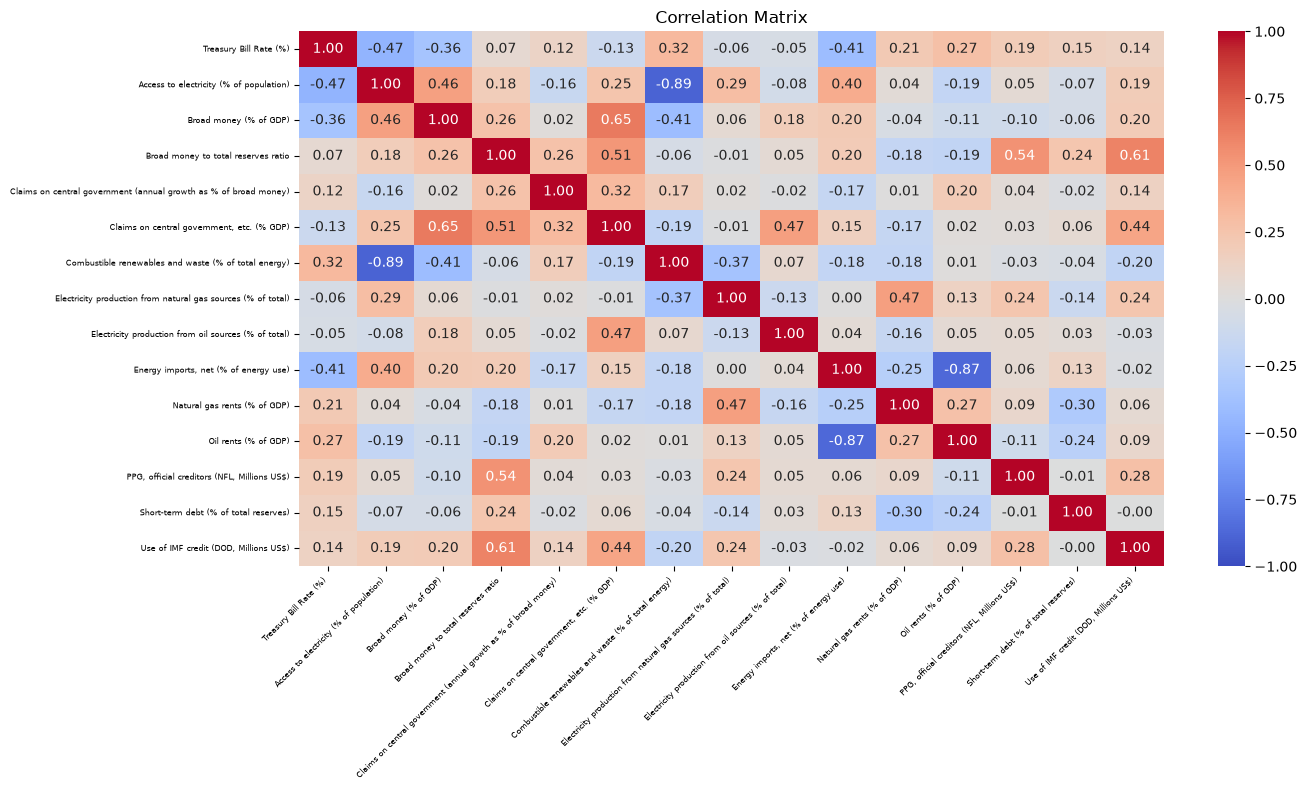

In [397]:

#Creating a correlation Matrix
#Once again defining Selected Variables

y_variable = response_variable
x_variables = time_independent_variables

# Select the variables and remove rows with missing values
correlation_data = df_wide[
    [y_variable] + x_variables
].dropna()

#Creating the correlation Matrix
corr_matrix = correlation_data.corr()

#Plotting the Correlation Matrix
plt.figure(figsize=(14, 8))     

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.xticks(fontsize=6, rotation=45, ha="right")
plt.yticks(fontsize=6, rotation=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

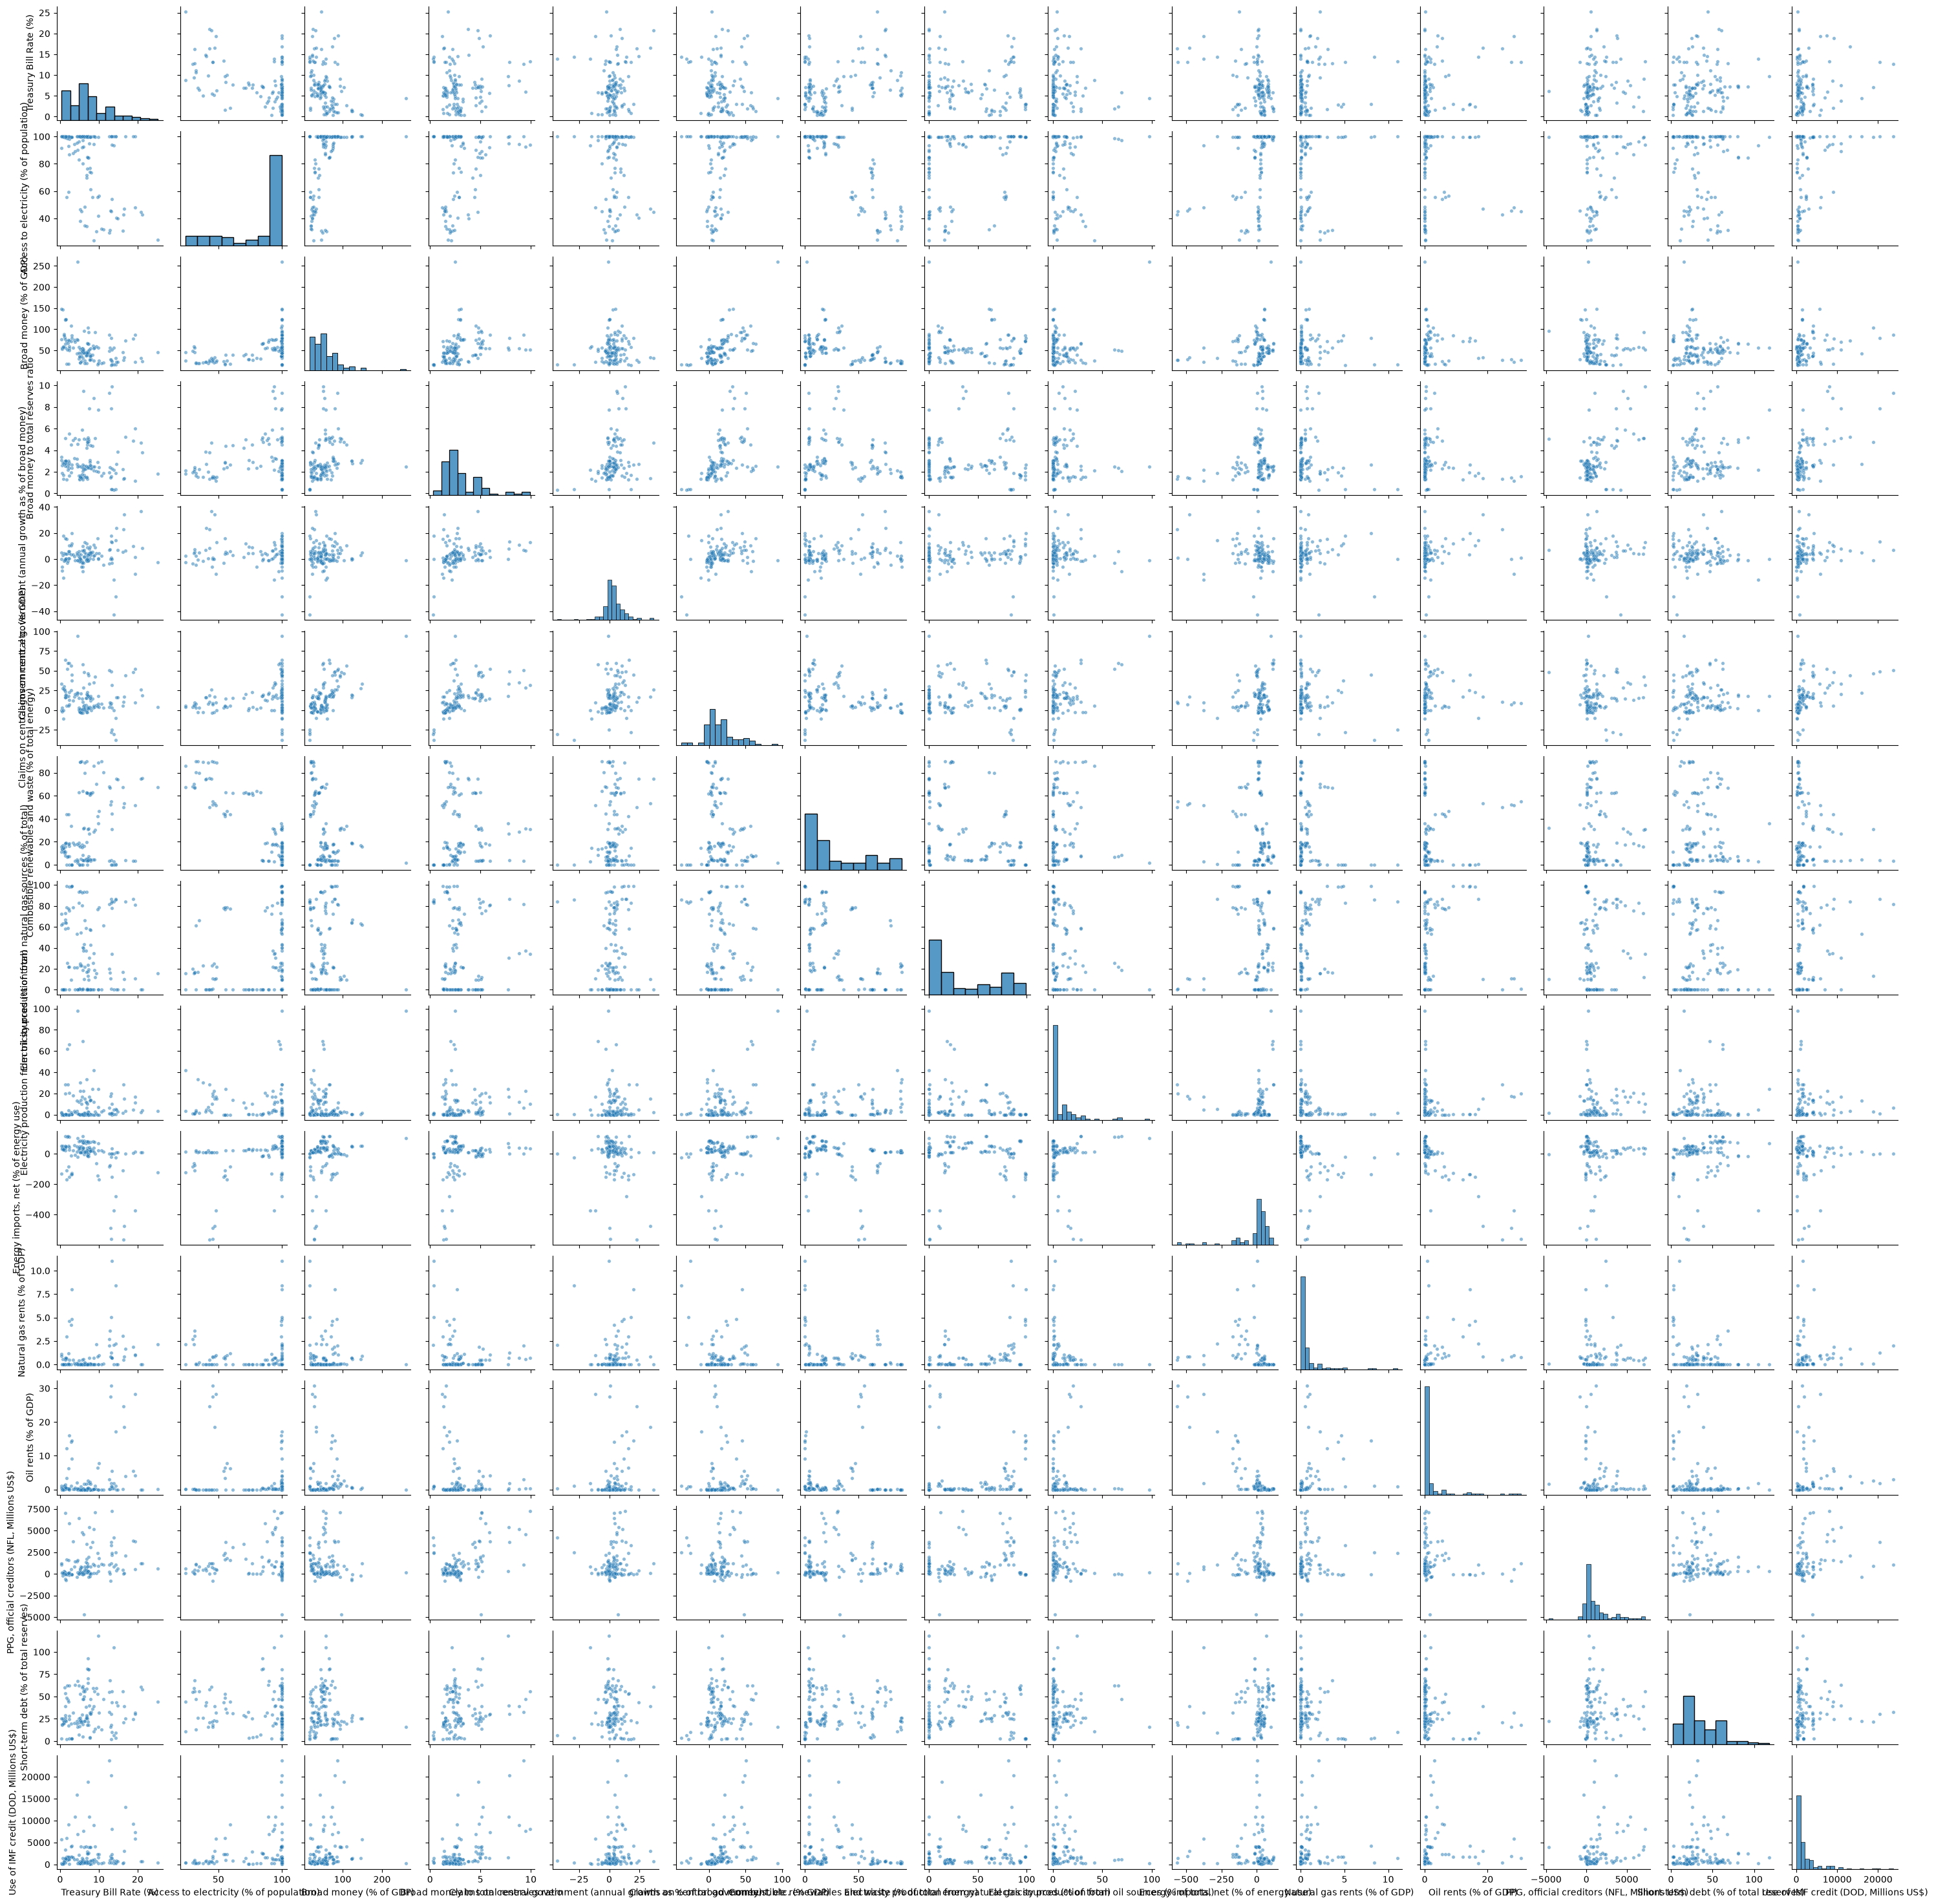

In [398]:
y_variable = response_variable
x_variables = time_independent_variables

# Select the variables and remove rows with missing values
correlation_data = df_wide[
    [y_variable] + x_variables
].dropna()

# Create scatter plot matrix
sns.pairplot(
    correlation_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 15},
    height=2
)
plt.show()

In [399]:
years_list = ["2017", "2018", "2019", "2020", "2021", "2022","2023",]
for i in years_list:
    regression_cycle(folder_location = regression_location, response_variable = response_variable, explanitory_variables= time_independent_variables, year=i, dataframe= df_transposed)


Year 2017: Maximum VIF = 14.7460. Evaluating variable removal.
Year 2017: Removing Broad money (% of GDP) (Maximum VIF = 14.7460)
Year 2017: Maximum VIF = 14.5609. Evaluating variable removal.
Year 2017: Removing Electricity production from oil sources (% of total) (Maximum VIF = 14.5609)
Year 2017: Maximum VIF = 14.1467. Evaluating variable removal.
Year 2017: Removing Oil rents (% of GDP) (Maximum VIF = 14.1467)
Year 2017: Maximum VIF = 14.1464. Evaluating variable removal.
Year 2017: Removing Claims on central government, etc. (% GDP) (Maximum VIF = 14.1464)
Year 2017: Maximum VIF = 13.2005. Evaluating variable removal.
Year 2017: Removing Claims on central government (annual growth as % of broad money) (Maximum VIF = 13.2005)
Year 2017: Maximum VIF = 12.9958. Evaluating variable removal.
Year 2017: Removing Combustible renewables and waste (% of total energy) (Maximum VIF = 12.9958)
Year 2017: Maximum VIF = 4.6615. Evaluating variable removal.
Year 2017: Removing Energy imports, ne

In [400]:

transformed_data, lambda_ = boxcox(df_wide["Treasury Bill Rate (%)"])
print("Lambda:", lambda_)
df_wide["Treasury Bill Rate (Norm) (%)"] = df_wide["Treasury Bill Rate (%)"]**0.35137265153722946
# Choose the indicator
indicator = "Treasury Bill Rate (Norm) (%)"


Lambda: 0.3553638338578089


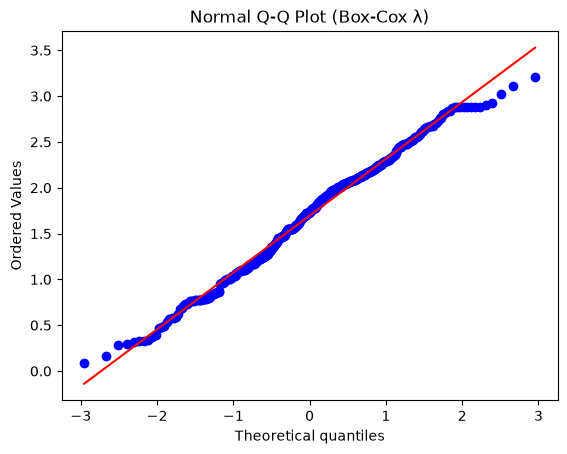

In [401]:

import scipy.stats as stats

stats.probplot(df_wide["Treasury Bill Rate (Norm) (%)"], dist="norm", plot=plt)
plt.title(f"Normal Q-Q Plot (Box-Cox λ)")
plt.show()